# Tugas 1 - kNN untuk Klasifikasi Jenis Suara

**Nama:** Radit Firansah  
**NIM:** 244107020196

Klasifikasi jenis suara male/female pada dataset voice.csv menggunakan kNN, mencari fitur dan nilai k terbaik.

## 1. Load Data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

data = pd.read_csv('../data/voice.csv')
data.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


## 2. Eksplorasi Data

In [2]:
data.info()
data['label'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   obje

label
male      1584
female    1584
Name: count, dtype: int64

## 3. Encoding Label

Label `male`/`female` diubah menjadi angka dengan `LabelEncoder`.

In [3]:
le = LabelEncoder()
data['label'] = le.fit_transform(data['label'])

print('Kelas:', list(le.classes_))
data['label'].value_counts()

Kelas: ['female', 'male']


label
1    1584
0    1584
Name: count, dtype: int64

## 4. Percobaan Berbagai Subset Fitur

Kita mencoba beberapa kombinasi fitur akustik untuk melihat mana yang memberi akurasi terbaik.

In [4]:
subsets = {
    'Semua fitur': list(data.columns[:-1]),
    'meanfreq, sd, meanfun, minfun, maxfun, IQR': ['meanfreq', 'sd', 'meanfun', 'minfun', 'maxfun', 'IQR'],
    'meanfun saja': ['meanfun'],
    'meanfun, sd': ['meanfun', 'sd'],
    'meanfreq, meanfun, sd': ['meanfreq', 'meanfun', 'sd'],
    'meanfun, minfun, maxfun': ['meanfun', 'minfun', 'maxfun'],
}

y = data['label']

for nama, fitur in subsets.items():
    X = data[fitur]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=42, stratify=y)

    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    model = KNeighborsClassifier(n_neighbors=5)
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))

    print(f'{nama:45s} -> akurasi: {acc:.4f}')

Semua fitur                                   -> akurasi: 0.9737
meanfreq, sd, meanfun, minfun, maxfun, IQR    -> akurasi: 0.9821
meanfun saja                                  -> akurasi: 0.9527
meanfun, sd                                   -> akurasi: 0.9548
meanfreq, meanfun, sd                         -> akurasi: 0.9674
meanfun, minfun, maxfun                       -> akurasi: 0.9674


## 5. Jawaban: Fitur yang Digunakan dan Alasannya

Berdasarkan percobaan di atas, subset fitur terbaik adalah **`meanfreq, sd, meanfun, minfun, maxfun, IQR`** dengan akurasi tertinggi.

Alasannya, fitur-fitur tersebut menggambarkan karakteristik dasar sinyal suara yang membedakan suara pria dan wanita:
- `meanfun` (mean fundamental frequency) dan `minfun`/`maxfun` (frekuensi fundamental minimum/maksimum) adalah pembeda utama, karena suara wanita umumnya memiliki frekuensi dasar lebih tinggi.
- `meanfreq` (rata-rata frekuensi) dan `sd` (standar deviasi frekuensi) menggambarkan sebaran frekuensi suara.
- `IQR` (interquartile range) menggambarkan rentang variasi frekuensi.

Dengan hanya memakai fitur-fitur yang relevan ini, akurasi justru lebih baik daripada memakai semua fitur, karena fitur yang tidak relevan hanya menambah noise pada perhitungan jarak kNN.

## 6. Mencari Nilai k Terbaik

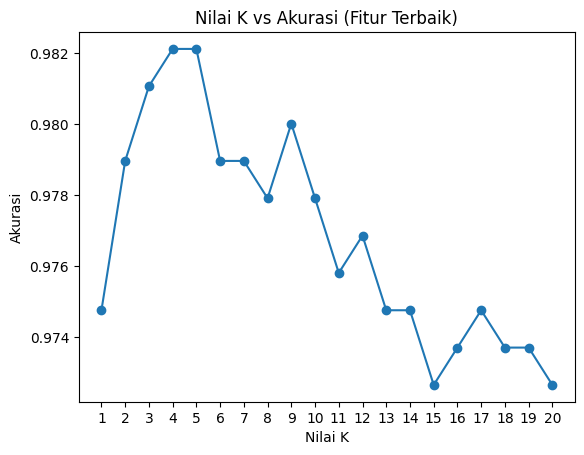

Nilai k terbaik : 4
Akurasi terbaik : 0.9821


In [5]:
fitur_terbaik = ['meanfreq', 'sd', 'meanfun', 'minfun', 'maxfun', 'IQR']
X = data[fitur_terbaik]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

akurasi = []
for k in range(1, 21):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    akurasi.append(accuracy_score(y_test, model.predict(X_test)))

plt.plot(range(1, 21), akurasi, marker='o')
plt.title('Nilai K vs Akurasi (Fitur Terbaik)')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.xticks(range(1, 21))
plt.show()

k_terbaik = akurasi.index(max(akurasi)) + 1
print('Nilai k terbaik :', k_terbaik)
print('Akurasi terbaik :', round(max(akurasi), 4))

## 7. Jawaban: Nilai k Terbaik

Dari grafik di atas, nilai **k terbaik adalah 4** (akurasi sekitar 0,9821). Nilai k kecil (seperti k=1) membuat model sensitif terhadap noise, sedangkan nilai k yang terlalu besar membuat batas keputusan terlalu halus dan akurasi menurun. Nilai k=4 memberikan keseimbangan terbaik antara bias dan variansi pada dataset ini.